# Solution: Mission 02 — MongoDB Operations Desk

This notebook is one possible solution. Try the mission yourself before you read it.

In [1]:
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from pymongo import ASCENDING, MongoClient

sys.path.insert(0, str(Path.cwd().parent.parent / "tools"))
import datasets

datasets.ensure_service("db", "mongodb")
client = MongoClient("mongodb://localhost:27017", serverSelectionTimeoutMS=20_000)
db = client["support_desk"]

import random
from datetime import datetime, timedelta

def make_tickets(n: int = 2000, seed: int = 7) -> list[dict]:
    """Synthetic support tickets (no real people): users, priorities, and a message history per ticket."""
    rnd = random.Random(seed)
    start = datetime(2025, 1, 1)
    tickets = []
    for i in range(1, n + 1):
        opened = start + timedelta(minutes=rnd.randint(0, 365 * 24 * 60))
        priority = rnd.choices(["low", "medium", "high", "urgent"], [40, 35, 20, 5])[0]
        status = rnd.choices(["open", "pending", "closed"], [25, 15, 60])[0]
        messages = [{"author": "customer", "at": opened, "text": "Problem report"}]
        if status != "open" or rnd.random() < 0.5:
            speed = {"urgent": 30, "high": 120, "medium": 480, "low": 1440}[priority]
            first_reply = opened + timedelta(minutes=rnd.expovariate(1 / speed))
            messages.append({"author": "agent", "at": first_reply, "text": "We are looking into it"})
            for k in range(rnd.randint(0, 4)):
                messages.append({"author": rnd.choice(["customer", "agent"]),
                                 "at": messages[-1]["at"] + timedelta(minutes=rnd.randint(5, 600)), "text": f"follow-up {k}"})
        tickets.append({"ticket_id": i, "user": {"id": rnd.randint(1, 300), "region": rnd.choice(["EU", "US", "APAC"]),
                                                 "plan": rnd.choice(["free", "pro", "enterprise"])},
                        "subject": rnd.choice(["login", "billing", "bug", "feature request", "performance"]),
                        "priority": priority, "status": status, "opened_at": opened, "messages": messages})
    return tickets

tickets = make_tickets()
print(len(tickets), "synthetic tickets")

2000 synthetic tickets


## Task 1: Document Design

**Design decision.** One document per ticket, with the **messages embedded** as an array: the desk always reads a ticket together with its history, a ticket has a small, bounded number of messages, and messages never belong to another ticket. The **user** is embedded as a small snapshot (`id`, `region`, `plan`) because the desk filters on these fields constantly; the full user profile would live in a separate `users` collection, referenced by `user.id`, because it is shared by many tickets and changes independently.

In [2]:
ALLOWED_PRIORITIES = {"low", "medium", "high", "urgent"}
ALLOWED_STATUS = {"open", "pending", "closed"}
REQUIRED = ("ticket_id", "user", "subject", "priority", "status", "opened_at", "messages")

def create_ticket_document(ticket: dict) -> dict:
    """Validate a ticket and return the document to insert into MongoDB."""
    missing = [k for k in REQUIRED if k not in ticket]
    if missing:
        raise ValueError(f"ticket {ticket.get('ticket_id')}: missing fields {missing}")
    if ticket["priority"] not in ALLOWED_PRIORITIES:
        raise ValueError(f"ticket {ticket['ticket_id']}: invalid priority {ticket['priority']!r}")
    if ticket["status"] not in ALLOWED_STATUS:
        raise ValueError(f"ticket {ticket['ticket_id']}: invalid status {ticket['status']!r}")
    if not {"id", "region"} <= set(ticket["user"]):
        raise ValueError(f"ticket {ticket['ticket_id']}: user needs id and region")
    doc = dict(ticket)
    doc["_id"] = doc.pop("ticket_id")                       # the ticket number is the natural primary key
    doc["message_count"] = len(doc["messages"])
    return doc

for bad in [{"ticket_id": 0}, {**tickets[0], "priority": "critical"}]:
    try:
        create_ticket_document(bad)
    except ValueError as err:
        print("rejected:", err)

rejected: ticket 0: missing fields ['user', 'subject', 'priority', 'status', 'opened_at', 'messages']
rejected: ticket 1: invalid priority 'critical'


## Task 2: Create

In [3]:
db.tickets.drop()
db.tickets_archive.drop()
db.tickets.insert_many([create_ticket_document(t) for t in tickets])
print("documents:", db.tickets.count_documents({}))

documents: 2000


## Task 3: Read with Nested Fields

In [4]:
QUERY = {"status": "open", "priority": {"$in": ["high", "urgent"]}, "user.region": "EU", "user.plan": "enterprise"}
print("open high/urgent EU enterprise tickets:", db.tickets.count_documents(QUERY))
print("tickets where the customer wrote a follow-up (array query):",
      db.tickets.count_documents({"messages": {"$elemMatch": {"author": "customer", "text": {"$regex": "^follow-up"}}}}))

open high/urgent EU enterprise tickets: 17
tickets where the customer wrote a follow-up (array query): 991


## Task 4: Update

In [5]:
now = datetime(2026, 1, 2, 9, 0)
res = db.tickets.update_many(
    {"status": "open", "priority": "urgent"},
    {"$set": {"assignee": "agent-oncall", "status": "pending"},
     "$push": {"messages": {"author": "agent", "at": now, "text": "Escalated to on-call agent"}},
     "$inc": {"message_count": 1}})
print("urgent tickets escalated:", res.modified_count)
print("open urgent tickets left:", db.tickets.count_documents({"status": "open", "priority": "urgent"}))

urgent tickets escalated: 27
open urgent tickets left: 0


## Task 5: Archive and Delete

In [6]:
old_closed = {"status": "closed", "opened_at": {"$lt": datetime(2025, 4, 1)}}
to_archive = list(db.tickets.find(old_closed))
if to_archive:
    db.tickets_archive.insert_many(to_archive)
deleted = db.tickets.delete_many(old_closed).deleted_count
print(f"archived {db.tickets_archive.count_documents({})}, deleted {deleted}, remaining {db.tickets.count_documents({})}")

archived 276, deleted 276, remaining 1724


Archive first, delete second: if the delete fails, the data still exists in both places, never in neither. (For full safety, MongoDB supports multi-document transactions on replica sets.)

## Task 6: Aggregations

In [7]:
def summarize_tickets(collection) -> pd.DataFrame:
    """Return the number of open tickets per region and priority."""
    rows = collection.aggregate([
        {"$match": {"status": "open"}},
        {"$group": {"_id": {"region": "$user.region", "priority": "$priority"}, "tickets": {"$sum": 1}}},
    ])
    df = pd.DataFrame([{**r["_id"], "tickets": r["tickets"]} for r in rows])
    table = df.pivot(index="region", columns="priority", values="tickets")
    return table.reindex(columns=["urgent", "high", "medium", "low"]).fillna(0).astype(int)

summarize_tickets(db.tickets)

priority,urgent,high,medium,low
region,,,,
APAC,0,48,61,76
EU,0,31,54,71
US,0,54,71,71


priority
urgent      30.0
high        76.0
medium     342.0
low       1040.0


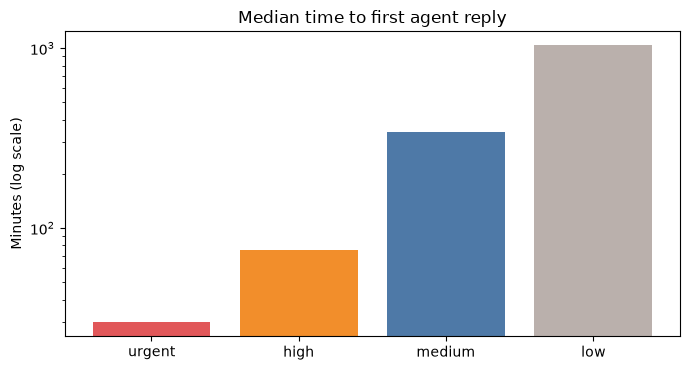

In [8]:
first_reply = pd.DataFrame(db.tickets.aggregate([
    {"$project": {"priority": 1, "opened_at": 1,
                  "first_agent": {"$first": {"$filter": {"input": "$messages", "cond": {"$eq": ["$$this.author", "agent"]}}}}}},
    {"$match": {"first_agent": {"$ne": None}}},
    {"$project": {"priority": 1, "minutes": {"$divide": [{"$subtract": ["$first_agent.at", "$opened_at"]}, 60_000]}}},
]))
order = ["urgent", "high", "medium", "low"]
med = first_reply.groupby("priority")["minutes"].median().reindex(order)
print(med.round(0).to_string())

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(med.index, med.values, color=["#E15759", "#F28E2B", "#4E79A7", "#BAB0AC"])
ax.set(yscale="log", title="Median time to first agent reply", ylabel="Minutes (log scale)")
plt.tight_layout()
plt.show()

The median reply time grows with lower priority, as the desk's service levels intend. Task 4 pushed an escalation message to the open urgent tickets; for an urgent ticket without an earlier agent reply, this message counts as its first reply, with a very long delay. The median is robust against such outliers, which is one reason to report medians for response times.

## Task 7: Index and `explain()`

In [9]:
def plan_stage(q):
    plan = db.tickets.find(q).explain()["queryPlanner"]["winningPlan"]
    stages = []
    while plan:
        stages.append(plan["stage"])
        plan = plan.get("inputStage")
    return stages

print("before:", plan_stage(QUERY))
db.tickets.create_index([("status", ASCENDING), ("user.region", ASCENDING), ("priority", ASCENDING)])
print("after :", plan_stage(QUERY))

before: ['COLLSCAN']


after : ['FETCH', 'IXSCAN']


The compound index follows the **equality → sort → range** rule: equality filters first (`status`, `user.region`), then the `$in` filter on `priority`.